### 02. Clinical Classification & Statistical Validation

This notebook evaluates the clinical validity of the EF estimation pipeline
across diagnostically relevant categories, comparing heuristic and
corrected predictions. Confusion matrices, ROC curves, AUC, and Cohen's
Kappa are computed as a baseline analysis, extended with bootstrap
confidence intervals and DeLong significance testing to formally assess
whether the learned correction provides a statistically meaningful
improvement.

All analyses in this notebook are performed on the TEST split only,
since it is the only subset untouched by both model training and the
outlier-filtering step, providing an unbiased estimate of real-world
performance.

- **Inputs:** `data/processed/inference_with_corrections.csv`
- **Outputs:** confusion matrices, ROC curves, and a summary statistics table
saved to `figures/`.

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv("../data/processed/inference_with_corrections.csv")
test = data[ data['split'] == 'TEST'].copy()

#### Clinical EF categories

EF thresholds used in clinical cardiology to distinguish principal
categories of ventricular function and associated pathologies:

- **Heart Failure with Reduced Ejection Fraction (HFrEF)**: LVEF ≤40%.
- **Heart Failure with Mid-Range Ejection Fraction (HFmrEF)**: LVEF 41–49%.
- **Heart Failure with Preserved Ejection Fraction (HFpEF)**: LVEF ≥50%.
  (Note: a clinical diagnosis of HFpEF also requires symptoms/signs of heart failure.)
- **Heart Failure with Improved Ejection Fraction (HFimpEF)**: defined as a
  previous LVEF ≤40% that has improved to >40%. (Note: clinical diagnosis needed.)
- **Normal Ejection Fraction**: typically 50–70%. Some sources provide
  slightly more precise ranges, such as 52–72% for males and 54–74% for females.
- **Hypertrophic Cardiomyopathy (HCM)**: characterized by unexplained left
  ventricular hypertrophy with a preserved or even increased ejection
  fraction, often above the normal range (>75%).

Since both HFpEF and HFimpEF require additional clinical assessment beyond
imaging-derived EF values alone, further analysis is restricted to the
remaining categories: **HFrEF, HFmrEF, Normal EF, and HCM** — consistent
with the scope of the original (unpublished) classification analysis.

In [2]:
def classify_ef(ef):
    if ef <= 40:
        return 'HFrEF'
    elif ef <= 49:
        return 'HFmrEF'
    elif ef <= 74:
        return 'Normal'
    else:
        return 'HCM'

test['true_class'] = test['true_ef'].apply(classify_ef)
test['heuristic_class'] = test['predicted_ef'].apply(classify_ef)
test['corrected_class'] = test['corrected_ef'].apply(classify_ef)

#### Confusion Matrices

In [3]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['HFrEF', 'HFmrEF', 'Normal', 'HCM']
cm_heuristic = confusion_matrix(test['true_class'], test['heuristic_class'], labels=labels)
cm_corrected = confusion_matrix(test['true_class'], test['corrected_class'], labels=labels)

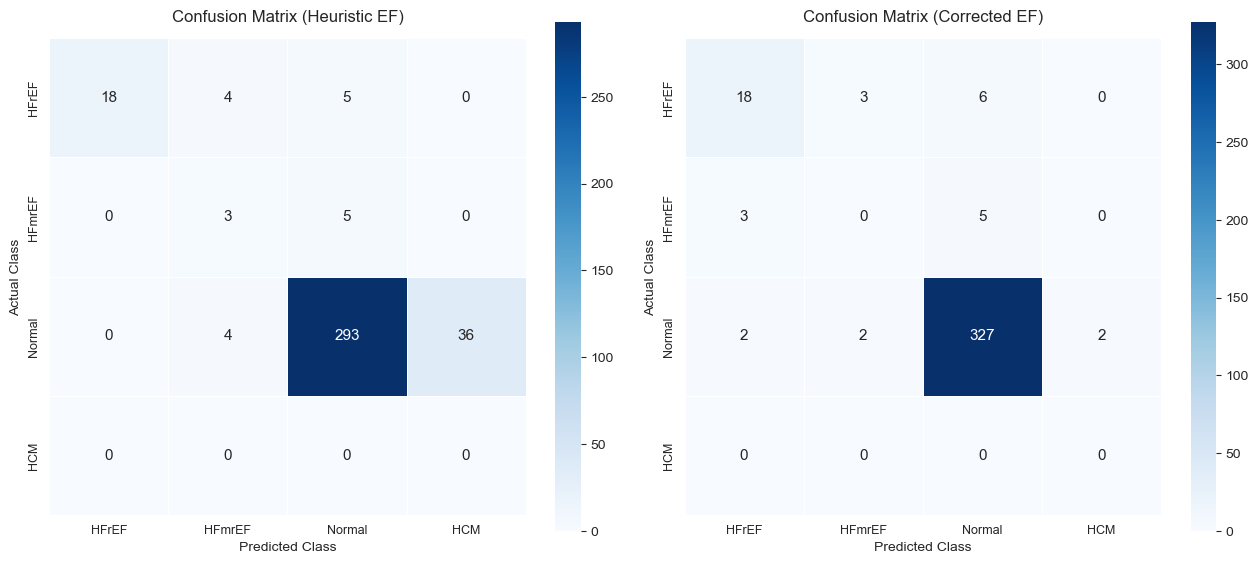

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, cm, title in zip(
    axes,
    [cm_heuristic, cm_corrected],
    ['Confusion Matrix (Heuristic EF)', 'Confusion Matrix (Corrected EF)']
):
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=labels, yticklabels=labels,
        cbar=True, square=True, linewidths=0.5, linecolor='white',
        annot_kws={"size": 11}, ax=ax
    )
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xlabel('Predicted Class', fontsize=10)
    ax.set_ylabel('Actual Class', fontsize=10)
    ax.tick_params(axis='both', labelsize=9)

plt.tight_layout()
plt.savefig('../figures/confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

"Hypertrophic CM" in both the "Heuristic EF" and "Corrected EF" confusion matrices, has all values in zero. This indicates that the test dataset contains no true positive cases for this category (no patients with EF > 75%).

In [5]:
count = 0

for ef in test['true_ef']:
    if ef > 75:
        count += 1
count

0

#### ROC curves by clinical category

Binary classification performance for HFrEF (≤40%), HFmrEF (41–49%), and
Normal EF (50–74%), comparing heuristic and corrected predictions.

Since these are threshold-based tasks derived from a continuous regression
output, the following scores are used as decision functions:
- **HFrEF**: negative EF (lower EF → higher HFrEF likelihood)
- **HFmrEF**: negative distance to the range midpoint (45%)
- **Normal**: negative distance to the range midpoint (62%)

AUC values are reported with bootstrap 95% confidence intervals.

In [6]:
from sklearn.metrics import roc_curve, roc_auc_score
from src.stats_utils import bootstrap_auc_ci

# Define binary tasks (true_label, heuristic_score, corrected_score)
tasks = {
    'HFrEF vs. Non-HFrEF (EF ≤40%)': {
        'y_true': (test['true_ef'] <= 40).astype(int),
        'score_heuristic': -test['predicted_ef'],
        'score_corrected': -test['corrected_ef'],
    },
    'HFmrEF vs. Non-HFmrEF (EF 41-49%)': {
        'y_true': ((test['true_ef'] > 40) & (test['true_ef'] <= 49)).astype(int),
        'score_heuristic': -np.abs(test['predicted_ef'] - 45),
        'score_corrected': -np.abs(test['corrected_ef'] - 45),
    },
    'Normal EF vs. Abnormal (EF 50-74%)': {
    'y_true': ((test['true_ef'] >= 50) & (test['true_ef'] <= 74)).astype(int),
    'score_heuristic': -np.abs(test['predicted_ef'] - 62),   # 62 = punto medio de 50-74
    'score_corrected': -np.abs(test['corrected_ef'] - 62),
    },
}

#### Visualization

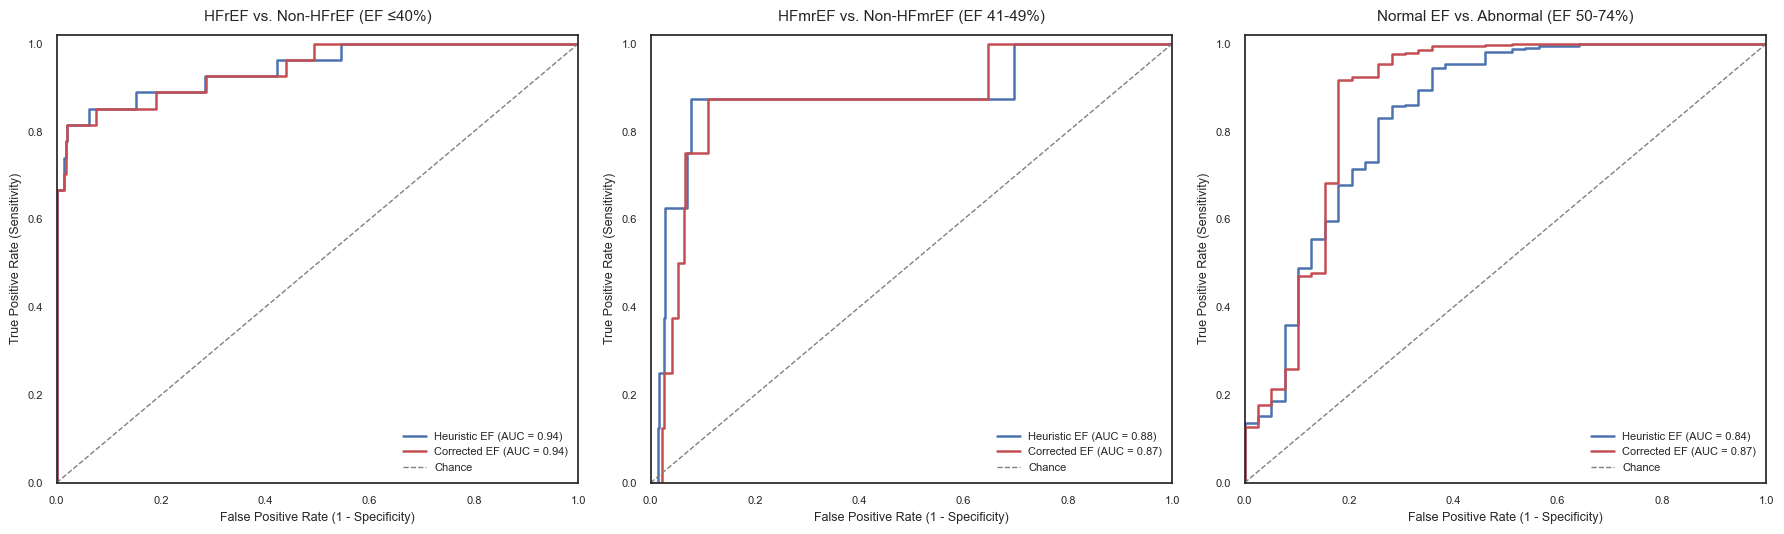

,AUC (Heuristic),CI (Heuristic),AUC (Corrected),CI (Corrected)
HFrEF vs. Non-HFrEF (EF ≤40%),0.943195,"(0.886, 0.989)",0.942326,"(0.886, 0.987)"
HFmrEF vs. Non-HFmrEF (EF 41-49%),0.880556,"(0.686, 0.982)",0.871181,"(0.695, 0.966)"
Normal EF vs. Abnormal (EF 50-74%),0.840231,"(0.758, 0.915)",0.87273,"(0.789, 0.948)"


In [7]:
sns.set_theme(style="white", font_scale=1.0)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

results = {}

for ax, (task_name, t) in zip(axes, tasks.items()):
    fpr_h, tpr_h, _ = roc_curve(t['y_true'], t['score_heuristic'])
    fpr_c, tpr_c, _ = roc_curve(t['y_true'], t['score_corrected'])

    auc_h = roc_auc_score(t['y_true'], t['score_heuristic'])
    auc_c = roc_auc_score(t['y_true'], t['score_corrected'])

    ci_h, _ = bootstrap_auc_ci(t['y_true'], t['score_heuristic'])
    ci_c, _ = bootstrap_auc_ci(t['y_true'], t['score_corrected'])

    results[task_name] = {
        'AUC (Heuristic)': auc_h, 'CI (Heuristic)': tuple(np.round(ci_h, 3)),
        'AUC (Corrected)': auc_c, 'CI (Corrected)': tuple(np.round(ci_c, 3)),
    }

    ax.plot(fpr_h, tpr_h, color='#4C72B0', lw=1.8, label=f'Heuristic EF (AUC = {auc_h:.2f})')
    ax.plot(fpr_c, tpr_c, color='#C44E52', lw=1.8, label=f'Corrected EF (AUC = {auc_c:.2f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=1, label='Chance')

    ax.set_title(task_name, fontsize=11, pad=10)
    ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=9)
    ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.legend(loc='lower right', fontsize=8, frameon=False)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig('../figures/roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame(results).T

AUC remains stable for HFrEF (0.94) and HFmrEF (~0.87-0.88), while Normal
EF shows the clearest improvement with correction (0.84 → 0.87), visible in
the tighter curve at low false-positive rates.

#### DeLong test

Since both AUCs are computed on the same TEST set, they are correlated and
cannot be compared with an independent-samples test. The DeLong test
accounts for this correlation.

For each category:
- H0: AUC_corrected = AUC_heuristic
- H1: AUC_corrected > AUC_heuristic (one-tailed, since the correction is
  expected to improve or maintain discrimination)
- alpha = 0.05

In [8]:
from src.stats_utils import delong_test

for task_name, t in tasks.items():
    z, p, auc_h, auc_c = delong_test(t['y_true'], t['score_heuristic'], t['score_corrected'])
    decision = "reject H0" if p < 0.05 else "fail to reject H0"
    print(f"{task_name}")
    print(f"  AUC heuristic={auc_h:.3f}  AUC corrected={auc_c:.3f}  z={z:.3f}  p={p:.4f}  -> {decision}")

HFrEF vs. Non-HFrEF (EF ≤40%)
  AUC heuristic=0.943  AUC corrected=0.942  z=-0.319  p=0.6251  -> fail to reject H0
HFmrEF vs. Non-HFmrEF (EF 41-49%)
  AUC heuristic=0.881  AUC corrected=0.871  z=-0.630  p=0.7358  -> fail to reject H0
Normal EF vs. Abnormal (EF 50-74%)
  AUC heuristic=0.840  AUC corrected=0.873  z=2.604  p=0.0046  -> reject H0


The DeLong test was applied to each of the three clinical categories to
formally assess whether the learned correction significantly improved
discriminative performance (one-tailed H1: AUC_corrected > AUC_heuristic,
alpha = 0.05).

For HFrEF and HFmrEF, the null hypothesis could not be rejected
(p = 0.625 and p = 0.736, respectively), indicating that the correction
neither improves nor degrades performance in these categories. This is
consistent with HFrEF already exhibiting near-ceiling discrimination
(AUC = 0.943) and with the limited statistical power available for HFmrEF
given its small sample size (n = 8 positive cases in TEST).

For Normal EF, the correction produced a statistically significant
improvement in discrimination (AUC 0.840 -> 0.873, z = 2.604, p = 0.0046).
This is the clearest evidence across
all categories that the learned correction provides a measurable clinical
benefit, consistent with the reduction in Normal-to-HCM misclassifications
observed in the confusion matrices.

#### Cohen's Kappa

Cohen's Kappa measures agreement between predicted and true clinical
categories, correcting for the agreement expected by chance given the
class distribution. This is particularly important here since the dataset
is heavily imbalanced toward Normal EF, which would inflate simple
accuracy without reflecting real diagnostic agreement.

The heuristic and corrected Kappa values are compared using a paired
bootstrap on their difference, following
the same rationale as the DeLong test:

- H0: kappa_corrected - kappa_heuristic = 0
- H1: kappa_corrected - kappa_heuristic > 0 (one-tailed)
- alpha = 0.05

In [11]:
from sklearn.metrics import cohen_kappa_score
from src.stats_utils import bootstrap_kappa_diff

kappa_heuristic = cohen_kappa_score(test['true_class'], test['heuristic_class'])
kappa_corrected = cohen_kappa_score(test['true_class'], test['corrected_class'])

print(f"Kappa (heuristic): {kappa_heuristic:.3f}")
print(f"Kappa (corrected): {kappa_corrected:.3f}")

diffs, (ci_low, ci_high), p_value = bootstrap_kappa_diff(
    test['true_class'], test['heuristic_class'], test['corrected_class']
)

print(f"\nDifference (corrected - heuristic): {diffs.mean():.3f}")
print(f"95% CI: [{ci_low:.3f}, {ci_high:.3f}]")
print(f"p-value: {p_value:.6f}")

Kappa (heuristic): 0.415
Kappa (corrected): 0.619

Difference (corrected - heuristic): 0.202
95% CI: [0.112, 0.302]
p-value: 0.000000


The 95% CI for the difference [0.112, 0.302] excludes zero and the
one-tailed p-value (p < 0.001) leads to rejection of H0. The corrected
model shows a statistically significant improvement in agreement with true
clinical categories (Kappa: 0.415 -> 0.619), moving from "moderate" to
"substantial" agreement per Landis & Koch (1977).

The corrected model matches or maintains discrimination performance for
HFrEF and HFmrEF (no statistically significant change), while providing a
significant improvement for Normal EF classification (AUC: 0.840 -> 0.873,
p = 0.0046) and for overall clinical agreement (Kappa: 0.415 -> 0.619,
p < 0.001). These results support the clinical utility of the learned
correction, particularly in reducing Normal-to-HCM misclassifications.